<a href="https://colab.research.google.com/github/202422/AI-Powered-Academic-Recovery-Dashboard/blob/main/ImprovabilityCompute.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Packages and Data loading**

In [267]:
import pandas as pd
import matplotlib.pyplot as plt

In [268]:
df_origin = pd.read_csv("/content/data_cleaned.csv")
df_origin

,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,...,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,FinalGrade
0,F,18,U,GT3,A,4,4,at_home,teacher,course,...,no,no,4,3,4,1,1,3,6,6
1,F,17,U,GT3,T,1,1,at_home,other,course,...,yes,no,5,3,3,1,1,3,4,6
2,F,15,U,LE3,T,1,1,at_home,other,other,...,yes,no,4,3,2,2,3,3,10,10
3,F,15,U,GT3,T,4,2,health,services,home,...,yes,yes,3,2,2,1,1,5,2,15
4,F,16,U,GT3,T,3,3,other,other,home,...,no,no,4,3,2,1,2,5,4,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
352,M,20,U,LE3,A,2,2,services,services,course,...,no,no,5,5,4,4,5,4,11,9
353,M,17,U,LE3,T,3,1,services,services,course,...,yes,no,2,4,5,3,4,2,3,16
354,M,21,R,GT3,T,1,1,other,other,course,...,no,no,5,5,3,3,3,3,3,7
355,M,18,R,LE3,T,3,2,services,other,course,...,yes,no,4,4,1,3,4,5,0,10


# **Compute**

In [269]:
df = df_origin.copy()

In [270]:
# -------- Group 1 --------
df["failures_risk"] = df["failures"] / 4
df["traveltime_risk"] = (df["traveltime"] - 1) / 3

df["Medu_risk"] = 1 - df["Medu"] / 4
df["Fedu_risk"] = 1 - df["Fedu"] / 4

job_risk = {
    "teacher": 0.0,
    "health": 0.2,
    "services": 0.4,
    "at_home": 0.6,
    "other": 0.8
}

df["Mjob_risk"] = df["Mjob"].map(job_risk)
df["Fjob_risk"] = df["Fjob"].map(job_risk)

df["address_risk"] = df["address"].map({"U": 0.0, "R": 1.0})

df["G1"] = (
    df["failures_risk"] +
    df["Mjob_risk"] +
    df["Fjob_risk"]
    # + df["Fedu_risk"]
    # + df["Medu_risk"]
    # + df["address_risk"]
    # + df["traveltime_risk"]
) / 3

# -------- Group 2 --------
df["absences_risk"] = df["absences"] / df["absences"].max()
df["studytime_risk"] = 1 - (df["studytime"] - 1) / 3
df["schoolsup_risk"] = df["schoolsup"].map({"yes": 0.0, "no": 1.0})
df["internet_risk"] = df["internet"].map({"yes": 0.0, "no": 1.0})
df["famsup_risk"] = df["famsup"].map({"yes": 0.0, "no": 1.0})

df["G2"] = (
    df["absences_risk"] +
    df["schoolsup_risk"] +
    df["studytime_risk"] +
    df["internet_risk"]
) / 4

# -------- Group 3 --------
df["health_risk"] = 1 - (df["health"] - 1) / 4
df["Walc_risk"] = (df["Walc"] - 1) / 4

df["G3"] = (df["health_risk"] + df["Walc_risk"]) / 2

# -------- Final SSCS --------
df["SSCS"] = 0.45 * df["G1"] + 0.4 * df["G2"] + 0.15 * df["G3"]


In [271]:
df["SSCS"] = 0.1* (df["failures_risk"]) + 0.1* df["studytime_risk"] + 0.3*(df["absences_risk"] + df["internet_risk"]) + 0.2*(df["famsup_risk"]+ df["Fjob_risk"]) + 0.3*(df["schoolsup_risk"]+df["health_risk"])

In [272]:
df[["SSCS", "FinalGrade"]].head(10)

,SSCS,FinalGrade
0,0.740667,6
1,0.692667,6
2,0.691667,10
3,0.421333,15
4,0.842667,10
5,0.566667,15
6,0.876667,11
7,0.690667,6
8,0.826667,19
9,0.526667,15


In [273]:
df["grade_norm"] = df["FinalGrade"] / 20

df["grade_complexity_factor"] = (
    0.5 + 4 * (df["grade_norm"] ** 2)
)

df["SSCS_final"] = df["SSCS"] * df["grade_complexity_factor"]

df["SSCS_final"] = df["SSCS_final"].max() - df["SSCS_final"]

In [274]:
df[["SSCS_final", "FinalGrade"]].head(20)

,SSCS_final,FinalGrade
0,3.445627,6
1,3.486907,6
2,3.045100,10
3,2.923933,15
4,2.818600,10
5,2.524267,15
6,2.583500,11
7,3.488627,6
8,0.685000,19
9,2.634267,15


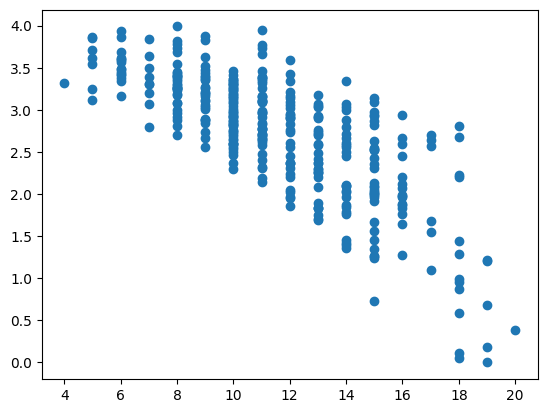

In [275]:
plt.scatter(df["FinalGrade"], df["SSCS_final"])